In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

ATTRIBUTIONS_PATH = "/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/attributions_validation_wrongness_metric2_output.csv"
HUMAN_SCORES_PATH = "/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/career_40_t_metric2/human_scores.csv"#"/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/career_40_t_metric1_v1/human_scores.csv"

attributions_df = pd.read_csv(ATTRIBUTIONS_PATH)
human_df = pd.read_csv(HUMAN_SCORES_PATH)



In [2]:

merged = pd.merge(
    attributions_df[["example_idx", "position", "token_text", "score"]],
    human_df[["example_idx", "position", "human_score"]],
    on=["example_idx", "position"],
).sort_values(["example_idx", "position"]).reset_index(drop=True)

print(merged)

    example_idx  position   token_text     score  human_score
0             2        83   transition  6.036624            3
1             2        84         into  1.072197            2
2             2        86   electrical  6.027796            4
3             2        97        spend  8.262431            8
4             2        99         your  2.453574            3
5             2       110        While  4.380324            3
6             2       117         part  3.652574            5
7             2       127         your  0.779123            2
8             3       113         hope  6.996379            5
9             3       127      sending  5.973294            7
10            3       129         mass  5.578141            7
11            3       132    companies  4.236498            6
12            3       137     approach  5.655451            2
13            3       138            .  0.002498            0
14            3       146       events  6.540095            8
15      

mean diff =  -0.48608690680888483
abs mean diff =  1.2566162242437187


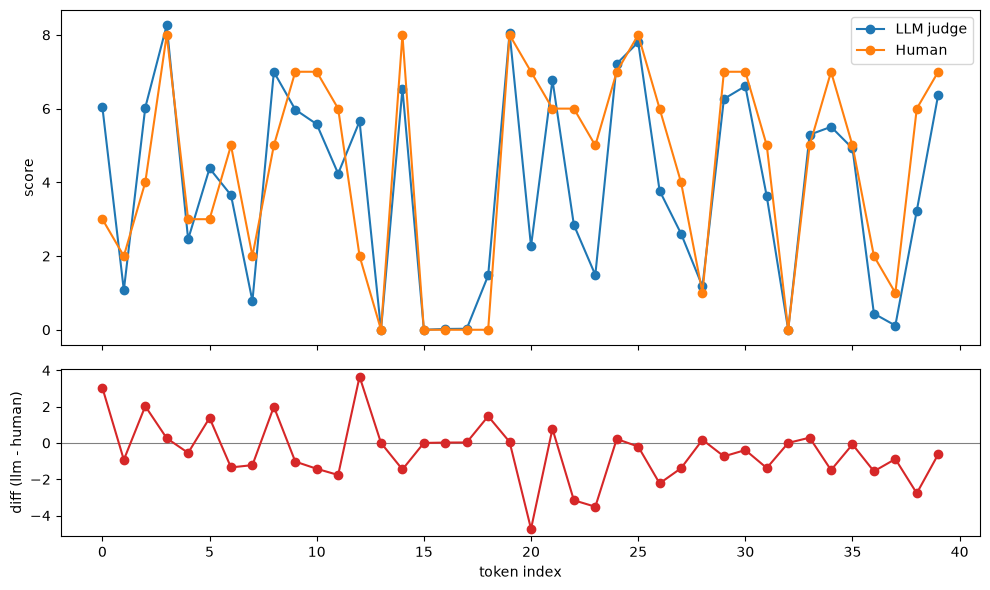

In [3]:



x = range(len(merged))
diff = merged["score"] - merged["human_score"]
print("mean diff = ", diff.mean())
print("abs mean diff = ", diff.abs().mean())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[2, 1])

ax1.plot(x, merged["score"], marker="o", label="LLM judge")
ax1.plot(x, merged["human_score"], marker="o", label="Human")
ax1.set_ylabel("score")
ax1.legend()

ax2.axhline(0, color="gray", linewidth=0.8)
ax2.plot(x, diff, marker="o", color="tab:red")
ax2.set_ylabel("diff (llm - human)")
ax2.set_xlabel("token index")

plt.tight_layout()
plt.show()

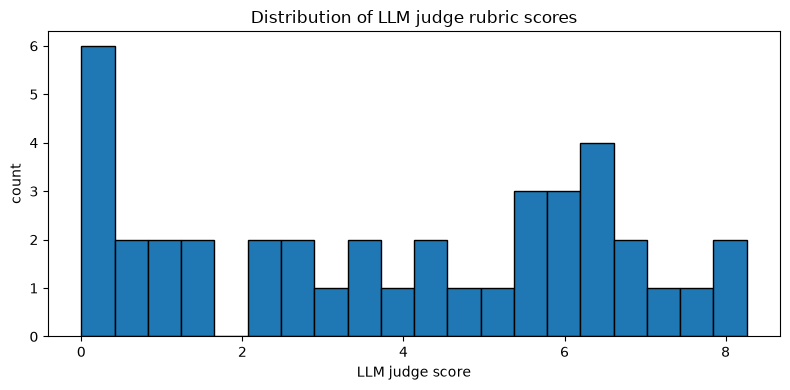

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(attributions_df["score"].dropna(), bins=20, edgecolor="black")
ax.set_xlabel("LLM judge score")
ax.set_ylabel("count")
ax.set_title("Distribution of LLM judge rubric scores")
plt.tight_layout()
plt.show()

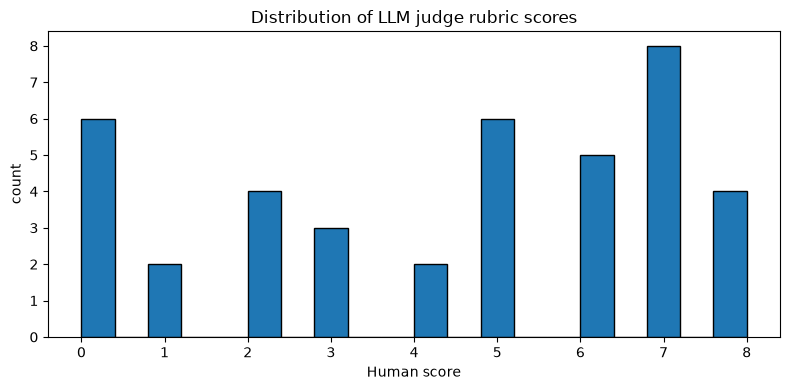

In [5]:

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(merged["human_score"].dropna(), bins=20, edgecolor="black")
ax.set_xlabel("Human score")
ax.set_ylabel("count")
ax.set_title("Distribution of LLM judge rubric scores")
plt.tight_layout()
plt.show()